# Домашнее задание №5 «Постройте posterior predictive distribution для эксперимента с подбрасываем монеты»

**Студент**: Сизиков Константин.

**Цель**: Поймет основы работы с библиотекой PyMC3.

**Описание/Пошаговая инструкция выполнения домашнего задания**:
 - Мы можем использовать апостериорное прогнозируемое распределение для предсказания того, что произойдет, если мы снова подбросим ту же монету.
 - Используйте sample_posterior_predictive для генерации выборки k, а затем используйте sns.hist для построения графика апостериорного предсказательного распределения.

> Примечание о версии. PyMC3 больше не развивается и не устанавливается на современные
> версии Python (3.10+). Используется его прямой наследник — **PyMC 5** (`import pymc as pm`).
> API для этой задачи практически совпадает: `pm.Model`, `pm.Beta`, `pm.Binomial`,
> `pm.sample`, `pm.sample_posterior_predictive`.

План:
1. Симулируем эксперимент: монета с неизвестной вероятностью орла θ, n бросков, k орлов.
2. Модель: θ ~ Beta(1, 1), k ~ Binomial(n, θ).
3. Сэмплируем апостериор θ | k с помощью NUTS.
4. Генерируем выборку k для повторного эксперимента через `sample_posterior_predictive`.
5. Строим гистограмму posterior predictive distribution (`sns.histplot`) и сравниваем
   с точным аналитическим ответом (бета-биномиальное распределение).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pymc as pm
import arviz as az
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4)
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

print(f"PyMC {pm.__version__}, ArviZ {az.__version__}, seaborn {sns.__version__}")

PyMC 5.28.5, ArviZ 0.23.4, seaborn 0.13.2


## 1. Данные эксперимента

Подбросим «нечестную» монету с истинной вероятностью орла θ = 0.35 сто раз.
В реальной жизни θ нам неизвестна — мы видим только число орлов `k`.

In [2]:
theta_true = 0.35   # истинная (скрытая) вероятность орла
n = 100             # число бросков

tosses = rng.binomial(1, theta_true, size=n)   # 1 = орёл, 0 = решка
k_obs = int(tosses.sum())

print("Первые 20 бросков:", tosses[:20])
print(f"Выпало орлов: k = {k_obs} из n = {n}  (доля {k_obs / n:.2f})")

Первые 20 бросков: [1 0 1 1 0 1 1 1 0 0 0 1 0 1 0 0 0 0 1 0]
Выпало орлов: k = 36 из n = 100  (доля 0.36)


## 2. Байесовская модель

* **Приор:** θ ~ Beta(1, 1) — равномерное распределение на [0, 1], никаких предпочтений.
* **Правдоподобие:** k ~ Binomial(n, θ).

Бета-приор сопряжён с биномиальным правдоподобием, поэтому апостериор известен точно:
θ | k ~ Beta(1 + k, 1 + n − k). Это позволит проверить результат MCMC.

In [3]:
alpha_prior, beta_prior = 1, 1

with pm.Model() as coin_model:
    theta = pm.Beta("theta", alpha=alpha_prior, beta=beta_prior)       # приор
    k = pm.Binomial("k", n=n, p=theta, observed=k_obs)                 # правдоподобие

    idata = pm.sample(draws=2000, tune=1000, chains=4,
                      random_seed=RANDOM_SEED, progressbar=False)

az.summary(idata, round_to=3)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [theta]


Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 1 seconds.


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
theta,0.363,0.047,0.279,0.453,0.001,0.0,3361.915,5470.941,1.001


`r_hat` ≈ 1.00 и `ess_bulk` в тысячи — цепочки сошлись, сэмплам можно доверять.
Посмотрим на трейс и апостериор θ и сравним его с точной формулой.

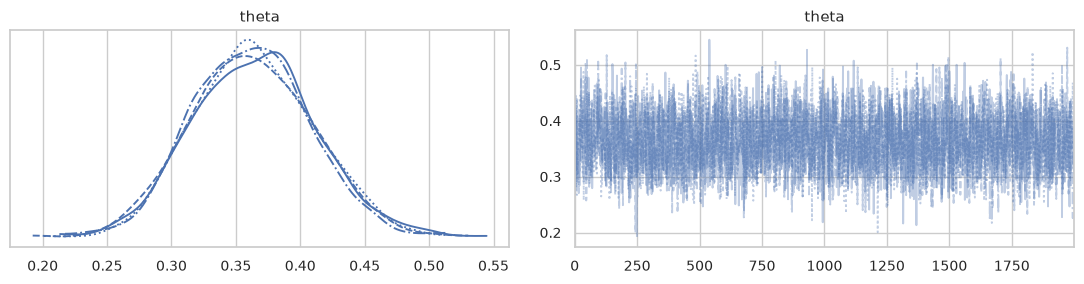

In [4]:
az.plot_trace(idata, figsize=(11, 3))
plt.tight_layout(); plt.show()

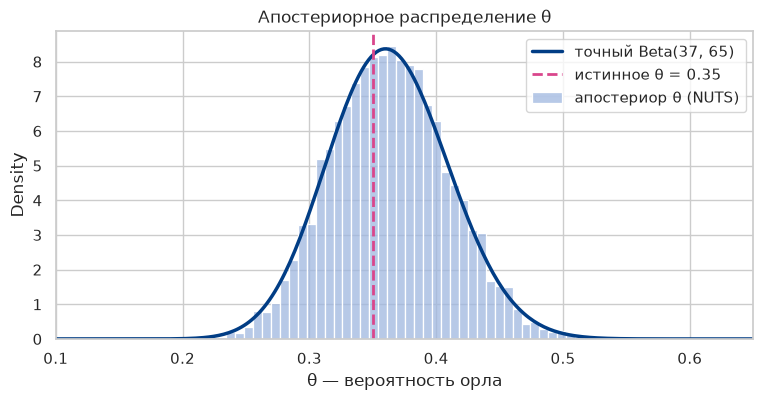

MCMC:  E[θ|k] = 0.3633,  94% HDI = [0.279, 0.453]
Точно: E[θ|k] = 0.3627


In [5]:
theta_samples = idata.posterior["theta"].to_numpy().ravel()
post_exact = stats.beta(alpha_prior + k_obs, beta_prior + n - k_obs)

grid = np.linspace(0, 1, 500)
fig, ax = plt.subplots()
sns.histplot(theta_samples, bins=50, stat="density", color="#9FB7E0", ax=ax,
             label="апостериор θ (NUTS)")
ax.plot(grid, post_exact.pdf(grid), color="#013D85", lw=2.5,
        label=f"точный Beta({alpha_prior + k_obs}, {beta_prior + n - k_obs})")
ax.axvline(theta_true, color="#D9468C", ls="--", lw=2, label=f"истинное θ = {theta_true}")
ax.set_xlim(0.1, 0.65); ax.set_xlabel("θ — вероятность орла"); ax.legend()
ax.set_title("Апостериорное распределение θ")
plt.show()

hdi = az.hdi(idata, hdi_prob=0.94)["theta"].values
print(f"MCMC:  E[θ|k] = {theta_samples.mean():.4f},  94% HDI = [{hdi[0]:.3f}, {hdi[1]:.3f}]")
print(f"Точно: E[θ|k] = {post_exact.mean():.4f}")

## 3. Posterior predictive: что будет, если подбросить ту же монету ещё раз?

Апостериорное прогнозное распределение:

$$
p(\tilde k \mid k) = \int p(\tilde k \mid \theta)\, p(\theta \mid k)\, d\theta .
$$

`sample_posterior_predictive` вычисляет этот интеграл методом Монте-Карло:
для каждого апостериорного сэмпла θ⁽ˢ⁾ генерируется новое k̃⁽ˢ⁾ ~ Binomial(n, θ⁽ˢ⁾).
Так в прогноз попадают **обе** неопределённости — и незнание θ, и случайность самих бросков.

In [6]:
with coin_model:
    idata.extend(pm.sample_posterior_predictive(idata, random_seed=RANDOM_SEED,
                                                progressbar=False))

k_pred = idata.posterior_predictive["k"].to_numpy().ravel()
print(f"Размер выборки k̃: {k_pred.size}")
print("Первые 15 значений:", k_pred[:15])

Sampling: [k]


Размер выборки k̃: 8000
Первые 15 значений: [32 44 40 37 33 38 30 33 38 23 42 32 35 39 23]


### Гистограмма posterior predictive distribution

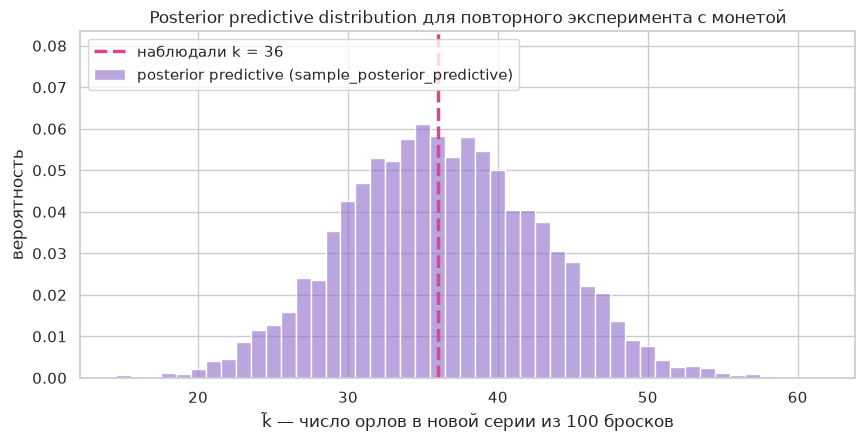

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(k_pred, discrete=True, stat="probability", color="#8D69CA", alpha=0.6,
             ax=ax, label="posterior predictive (sample_posterior_predictive)")
ax.axvline(k_obs, color="#D9468C", lw=2.5, ls="--", label=f"наблюдали k = {k_obs}")
ax.set_xlabel(f"k̃ — число орлов в новой серии из {n} бросков")
ax.set_ylabel("вероятность")
ax.set_title("Posterior predictive distribution для повторного эксперимента с монетой")
ax.set_ylim(0, ax.get_ylim()[1] * 1.3); ax.legend(loc="upper left")
plt.show()

### Проверка: сравнение с точным ответом и с «наивным» прогнозом

Для модели Beta–Binomial прогнозное распределение известно аналитически —
это **бета-биномиальное** распределение BetaBinom(n, 1 + k, 1 + n − k).

Для сравнения построим и «наивный» плагин-прогноз Binomial(n, θ̂), где вместо всего
апостериора подставлена одна точечная оценка θ̂ = k / n. Он игнорирует неопределённость в θ.

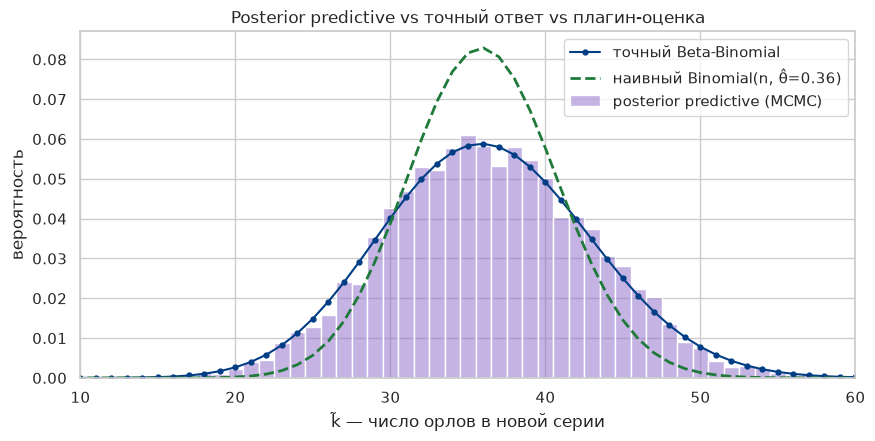

                              среднее  ст.откл.
MCMC posterior predictive       36.40      6.62
точный Beta-Binomial            36.27      6.73
наивный Binomial(n, k/n)        36.00      4.80

94% прогнозный интервал для k̃: [24, 49]
P(k̃ > 50) — что в новой серии орлов будет больше половины: 0.0164


In [8]:
ks = np.arange(0, n + 1)
pp_exact = stats.betabinom(n, alpha_prior + k_obs, beta_prior + n - k_obs)
plugin = stats.binom(n, k_obs / n)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(k_pred, discrete=True, stat="probability", color="#8D69CA", alpha=0.5,
             ax=ax, label="posterior predictive (MCMC)")
ax.plot(ks, pp_exact.pmf(ks), "o-", color="#013D85", ms=3.5, lw=1.5,
        label="точный Beta-Binomial")
ax.plot(ks, plugin.pmf(ks), "--", color="#1F7A3A", lw=2,
        label=f"наивный Binomial(n, θ̂={k_obs / n:.2f})")
ax.set_xlim(10, 60)
ax.set_xlabel("k̃ — число орлов в новой серии"); ax.set_ylabel("вероятность")
ax.legend(); ax.set_title("Posterior predictive vs точный ответ vs плагин-оценка")
plt.show()

lo, hi = np.percentile(k_pred, [3, 97])
print(f"{'':28s}{'среднее':>9s}{'ст.откл.':>10s}")
print(f"{'MCMC posterior predictive':28s}{k_pred.mean():9.2f}{k_pred.std():10.2f}")
print(f"{'точный Beta-Binomial':28s}{pp_exact.mean():9.2f}{pp_exact.std():10.2f}")
print(f"{'наивный Binomial(n, k/n)':28s}{plugin.mean():9.2f}{plugin.std():10.2f}")
print(f"\n94% прогнозный интервал для k̃: [{lo:.0f}, {hi:.0f}]")
print(f"P(k̃ > 50) — что в новой серии орлов будет больше половины: {(k_pred > 50).mean():.4f}")

### Posterior predictive check

Тот же инструмент используется для проверки модели: если модель адекватна,
наблюдённые данные должны выглядеть «типично» на фоне сгенерированных.
ArviZ строит такой график одной командой.

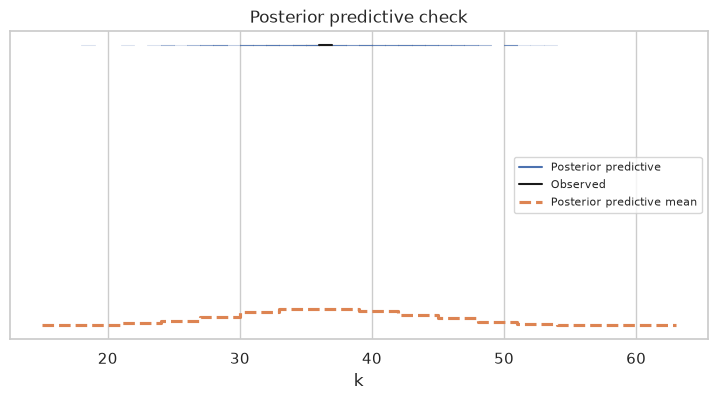

Байесовский p-value P(k̃ ≥ k_obs) = 0.541  (≈0.5 — наблюдение типично для модели)


In [9]:
az.plot_ppc(idata, kind="kde", num_pp_samples=200, figsize=(9, 4))
plt.title("Posterior predictive check")
plt.show()

p_value = (k_pred >= k_obs).mean()
print(f"Байесовский p-value P(k̃ ≥ k_obs) = {p_value:.3f}  (≈0.5 — наблюдение типично для модели)")

### Как прогноз зависит от объёма данных

Повторим всё для разного числа бросков (θ = 0.35), каждый раз предсказывая долю орлов
в новой серии той же длины. Чем больше наблюдали, тем уже апостериор θ и тем ближе
прогноз к «чисто биномиальному» разбросу.

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [theta]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 0 seconds.


Sampling: [k]


Initializing NUTS using jitter+adapt_diag...


... (5 outputs left out)

Multiprocess sampling (4 chains in 4 jobs)


NUTS: [theta]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 0 seconds.


Sampling: [k]


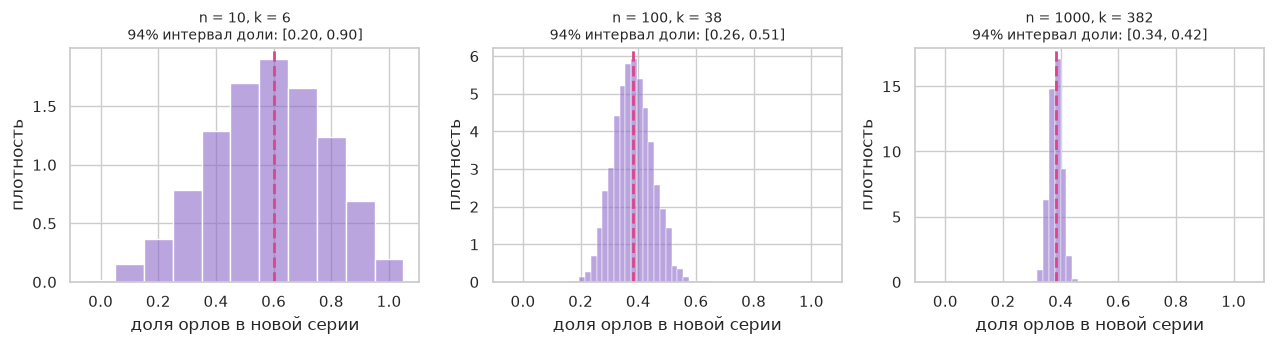

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
for ax, n_i in zip(axes, [10, 100, 1000]):
    k_i = int(rng.binomial(n_i, theta_true))
    with pm.Model():
        th = pm.Beta("theta", 1, 1)
        pm.Binomial("k", n=n_i, p=th, observed=k_i)
        id_i = pm.sample(1000, tune=1000, chains=4, random_seed=RANDOM_SEED,
                         progressbar=False)
        pp_i = pm.sample_posterior_predictive(id_i, random_seed=RANDOM_SEED,
                                              progressbar=False)
    share = pp_i.posterior_predictive["k"].to_numpy().ravel() / n_i
    step = max(1, n_i // 50)                       # бины выровнены по целым k
    edges = (np.arange(0, n_i + step + 1, step) - 0.5) / n_i
    sns.histplot(share, bins=edges, stat="density", color="#8D69CA", alpha=0.6, ax=ax)
    ax.axvline(k_i / n_i, color="#D9468C", ls="--", lw=2)
    lo_i, hi_i = np.percentile(share, [3, 97])
    ax.set_title(f"n = {n_i}, k = {k_i}\n94% интервал доли: [{lo_i:.2f}, {hi_i:.2f}]", fontsize=10)
    ax.set_xlabel("доля орлов в новой серии"); ax.set_ylabel("плотность")
plt.tight_layout(); plt.show()

## Выводы

1. **Модель в PyMC задаётся как генеративная история данных:** приор `pm.Beta` для
   вероятности орла θ и правдоподобие `pm.Binomial` с `observed=k`. Апостериор получен
   сэмплером NUTS (`pm.sample`); диагностика (`r_hat` ≈ 1.00, большой ESS, ровный трейс)
   показывает, что цепочки сошлись. Апостериорное среднее θ совпало с точным
   сопряжённым ответом Beta(1 + k, 1 + n − k), а истинное значение θ = 0.35 попало
   в 94% HDI.

2. **`sample_posterior_predictive` строит прогноз для повторного эксперимента:** для каждого
   сэмпла θ из апостериора генерируется новое число орлов k̃ в серии из n бросков.
   Гистограмма полученной выборки (`sns.histplot`) — это и есть posterior predictive
   distribution: она центрирована около наблюдённого k и показывает, какое число орлов
   правдоподобно ожидать при новом подбрасывании той же монеты, с 94% прогнозным интервалом.

3. **MCMC-прогноз совпал с аналитикой:** гистограмма практически повторяет точное
   бета-биномиальное распределение — и по среднему, и по разбросу.

4. **Прогнозное распределение шире «наивного» Binomial(n, k/n).** Оно учитывает два
   источника неопределённости: случайность самих бросков *и* то, что мы не знаем θ точно.
   Подстановка точечной оценки θ̂ занижает разброс прогноза и даёт излишне уверенные
   предсказания — в этом главное практическое преимущество байесовского подхода.

5. **Posterior predictive — ещё и инструмент проверки модели.** Наблюдённое значение
   лежит в центре прогнозного распределения (байесовский p-value около 0.5), то есть модель
   «биномиальная монета с постоянной θ» согласуется с данными.

6. **С ростом числа наблюдений неопределённость в θ уменьшается**, и прогноз доли орлов
   сужается: при n = 10 он охватывает почти весь отрезок [0, 1], при n = 1000 —
   узкую окрестность истинного значения 0.35.